# Tarea 4. Regresión lineal con descenso de gradiente

**Materia:** Inteligencia Artificial
**Profesor:** José Mario Ríos Félix
**Horario:** 6:00 a 7:00 p. m.
**Alumno:** Daniel Jimenez Duarte
**No. de control:** 23170198

Se ajusta una recta a datos reales del dataset **California Housing** para estimar el valor de una vivienda a partir del ingreso medio de su zona. El modelo se programa desde cero con NumPy.

## 1. Carga de datos

California Housing viene incluido en scikit-learn. Cada fila es una zona de California. Se usan las primeras 50 zonas para poder ver los puntos en la gráfica.

- `X`: ingreso medio de la zona (`MedInc`), en decenas de miles de dólares.
- `Y`: valor medio de las viviendas (`MedHouseVal`), en cientos de miles de dólares.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Carga el dataset como tabla
california = fetch_california_housing(as_frame=True)

# X = ingreso medio, Y = valor de la vivienda (primeras 50 zonas)
X = california.data['MedInc'].values[:50]
Y = california.target.values[:50]

print(f"Zonas cargadas: {len(X)}")

Zonas cargadas: 50


## 2. Parámetros del modelo

El modelo es una recta: `Y = w * X + b`.

- `w` es la pendiente: cuánto sube el valor de la vivienda por cada unidad de ingreso.
- `b` es la ordenada al origen: lo que predice el modelo cuando el ingreso es 0.
- `learning_rate` es el tamaño de cada paso de corrección.
- `epochs` es cuántas veces se repite el entrenamiento.

In [6]:
# Parámetros iniciales de la recta
w = 0.0
b = 0.0

# Hiperparámetros
learning_rate = 0.02
epochs = 2000
n = len(X)

# Guarda el error de cada época para graficarlo
historial_costos = []

## 3. Entrenamiento

En cada época se repiten cuatro pasos:

1. **Predecir** con los valores actuales de `w` y `b`.
2. **Medir el error** con el error cuadrático medio (MSE): el promedio de las diferencias entre lo predicho y lo real, elevadas al cuadrado.
3. **Calcular los gradientes** (derivadas del costo respecto a `w` y `b`), que indican hacia dónde moverlos para que el error baje.
4. **Actualizar** `w` y `b` en sentido contrario al gradiente, con pasos de tamaño `learning_rate`.

In [7]:
for epoch in range(epochs):
    # 1. Predicción
    Y_pred = w * X + b

    # 2. Costo (MSE)
    error = Y_pred - Y
    costo = np.sum(error ** 2) / (2 * n)
    historial_costos.append(costo)

    # 3. Gradientes
    dw = np.sum(error * X) / n
    db = np.sum(error) / n

    # 4. Actualiza los parámetros
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("Entrenamiento terminado")
print(f"Recta aprendida: Valor = {w:.4f} * Ingreso + {b:.4f}")

Entrenamiento terminado
Recta aprendida: Valor = 0.4416 * Ingreso + 0.6011


## 4. Resultado

Los puntos azules son las zonas reales y la línea roja es la recta que aprendió el modelo.

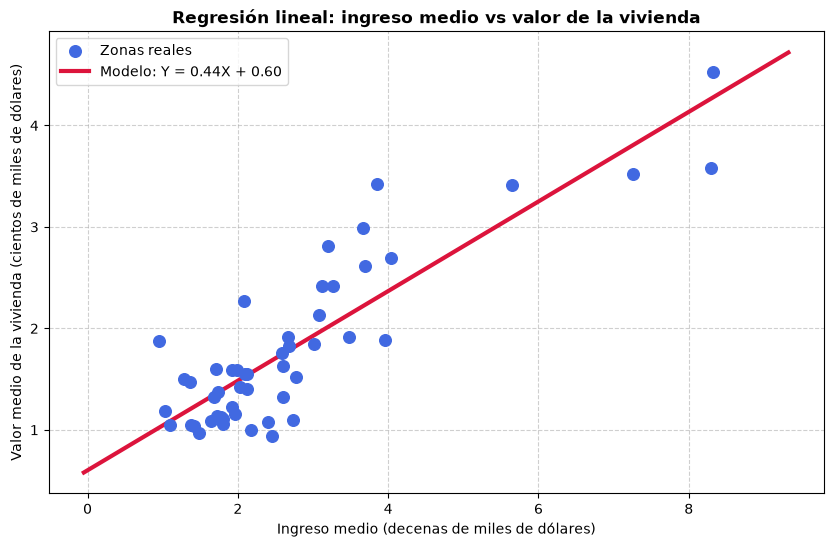

In [8]:
plt.figure(figsize=(10, 6))

# Puntos reales
plt.scatter(X, Y, color='royalblue', s=70, label='Zonas reales', zorder=5)

# Recta aprendida
X_linea = np.linspace(X.min() - 1, X.max() + 1, 100)
plt.plot(X_linea, w * X_linea + b, color='crimson', linewidth=3,
         label=f'Modelo: Y = {w:.2f}X + {b:.2f}')

plt.title('Regresión lineal: ingreso medio vs valor de la vivienda', fontweight='bold')
plt.xlabel('Ingreso medio (decenas de miles de dólares)')
plt.ylabel('Valor medio de la vivienda (cientos de miles de dólares)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 5. Evolución del costo

Si la curva baja y se aplana, el modelo terminó de aprender. Si siguiera bajando en la última época, faltarían épocas.

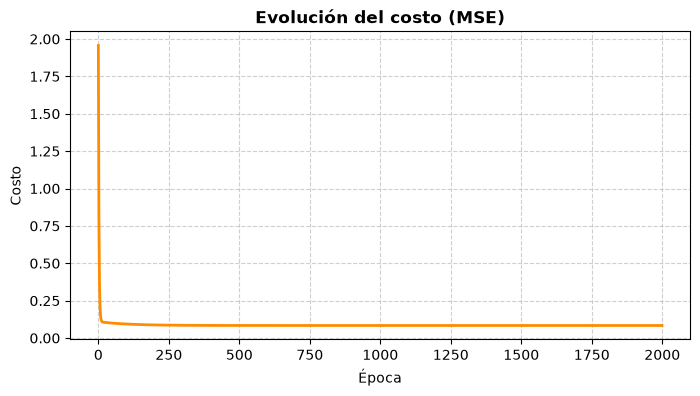

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución del costo (MSE)', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Costo')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 6. Comprobación con la solución exacta

La mejor recta posible para estos datos se puede obtener directamente con mínimos cuadrados (`np.polyfit`). Si el descenso de gradiente funcionó, debe llegar a casi los mismos valores.

In [10]:
# Solución exacta por mínimos cuadrados
w_exacta, b_exacta = np.polyfit(X, Y, 1)

print(f"Descenso de gradiente: w = {w:.4f}, b = {b:.4f}")
print(f"Mínimos cuadrados    : w = {w_exacta:.4f}, b = {b_exacta:.4f}")

Descenso de gradiente: w = 0.4416, b = 0.6011
Mínimos cuadrados    : w = 0.4416, b = 0.6012


## Interpretación de los resultados

La recta aprendida es **Valor = 0.4416 · Ingreso + 0.6011**, casi igual a la solución exacta
(0.4416 · Ingreso + 0.6012), así que el descenso de gradiente llegó al resultado correcto.

Como el ingreso está en decenas de miles de dólares y el valor de la vivienda en cientos de miles, la
pendiente se lee así: por cada 10,000 dólares más de ingreso medio en la zona, el modelo estima unos
4,416 dólares más en el valor de la vivienda.

La ordenada al origen (0.6011) sería el valor de una vivienda en una zona con ingreso cero. Como el
ingreso mínimo de estos datos es 0.95, ese punto queda fuera del rango observado y no tiene una
interpretación práctica.

El costo bajó de 1.96 en la primera época a 0.10 en la época 50, y de ahí se fue
aplanando hasta 0.08. Esto indica que 2000 épocas fueron suficientes para este conjunto.

Los puntos muestran que las zonas con más ingreso tienden a tener viviendas más caras, pero hay
dispersión: el ingreso por sí solo no explica todo el valor de una vivienda.